# Oil & Gas Refinery Capacity & Fuel Access — Africa vs USA
### Exploratory Data Analysis

Africa holds roughly 7% of the world's proven crude oil reserves, yet for decades its largest producers have shipped crude abroad and imported refined petrol, diesel and jet fuel back — often from Europe, India and the **United States** Gulf Coast. This notebook explores that *refining gap* and its knock-on effects on fuel and energy access using six World Bank indicators for 14 African countries and the USA.

**Data:** `data/oil_gas_refinery.db` produced by `src/loading/load.py` (World Bank Open Data API).

| Indicator | World Bank code | Coverage in this build |
|---|---|---|
| Oil rents (% GDP) | `NY.GDP.PETR.RT.ZS` | 2012–2021 |
| Fuel exports (% merchandise exports) | `TX.VAL.FUEL.ZS.UN` | 2016–2025 |
| Fuel imports (% merchandise imports) | `TM.VAL.FUEL.ZS.UN` | 2016–2025 |
| Access to electricity (% population) | `EG.ELC.ACCS.ZS` | 2015–2024 |
| Fossil fuel energy consumption (% total) | `EG.USE.COMM.FO.ZS` | 2015 only (series discontinued) |
| GDP per capita (current US$) | `NY.GDP.PCAP.CD` | 2016–2025 |

> **Refining-gap proxy.** Country-level refinery throughput is not published by the World Bank, so we use a trade-based signal: a country whose merchandise exports are ≥ 50% fuel (*it produces crude*) **and** whose imports are ≥ 15% fuel (*it buys back refined products*) is flagged as having a refining gap.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns

pio.renderers.default = "notebook_connected"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "oil_gas_refinery.db"
assert DB_PATH.exists(), f"Run the pipeline first: {DB_PATH} not found"

conn = sqlite3.connect(DB_PATH)
panel = pd.read_sql(
    """SELECT f.*, c.country, c.region, c.subregion, c.opec_member
       FROM fact_energy_indicators f JOIN dim_country c USING (iso3)""", conn)
latest = pd.read_sql(
    """SELECT s.*, c.country, c.region, c.subregion, c.opec_member
       FROM country_latest_snapshot s JOIN dim_country c USING (iso3)""", conn)
quality = pd.read_sql("SELECT * FROM data_quality_report", conn)

COLORS = {"Africa": "#d95f02", "North America": "#1b9e77"}
print(f"Panel: {panel.shape[0]} country-years, {panel['iso3'].nunique()} countries, "
      f"{panel['year'].min()}-{panel['year'].max()}")
quality

Panel: 209 country-years, 15 countries, 2012-2025


,indicator,rows,non_null,null_pct,imputed,countries_covered,min_year,max_year,min,max,mean
0,oil_rents_pct_gdp,209,144,31.10,0,15,2012,2021,0.0008,57.6301,8.1693
1,fuel_exports_pct_merchandise,209,116,44.50,3,14,2016,2025,0.0005,96.4782,37.0659
2,fuel_imports_pct_merchandise,209,116,44.50,3,14,2016,2025,1.2422,39.5617,14.6801
3,electricity_access_pct,209,150,28.23,0,15,2015,2024,4.2000,100.0000,72.2887
4,fossil_fuel_pct_energy,209,15,92.82,0,15,2015,2015,2.3328,82.3258,41.8933
5,gdp_per_capita_usd,209,140,33.01,0,14,2016,2025,431.0526,90026.5163,8519.1511


## 1. Data quality check

Before drawing conclusions it is worth knowing what is — and isn't — in the data:

* **Oil rents** stop at 2021 (the World Bank's latest natural-capital release).
* **Fossil fuel consumption** only has genuine values for 2015; later years were zero-filled placeholders in the API and are nulled in `transform.py`.
* **South Sudan** has no trade or GDP data, and Libya, Sudan and Algeria have multi-year trade gaps — conflict and reporting lags are themselves a signal of fragile fuel supply chains.

In [2]:
coverage = (panel.set_index(["country", "year"])
            [["oil_rents_pct_gdp", "fuel_exports_pct_merchandise", "fuel_imports_pct_merchandise",
              "electricity_access_pct", "gdp_per_capita_usd"]]
            .notna().groupby("country").sum())
coverage.columns = ["oil rents", "fuel exp", "fuel imp", "elec access", "GDP pc"]
coverage.sort_values("fuel imp")

,oil rents,fuel exp,fuel imp,elec access,GDP pc
country,,,,,
South Sudan,4,0,0,10,0
Sudan,10,3,3,10,10
Libya,10,4,4,10,10
Algeria,10,5,5,10,10
Gabon,10,8,8,10,10
Cameroon,10,8,8,10,10
DR Congo,10,9,9,10,10
Tunisia,10,9,9,10,10
Ghana,10,10,10,10,10


## 2. The crude-out, products-in paradox

Visualisation 1 places every country by its latest fuel-export share (x) and fuel-import share (y). The **top-right quadrant** is where the refining gap lives: economies that depend on crude for most of their export earnings yet spend a large slice of their import bill on fuel.

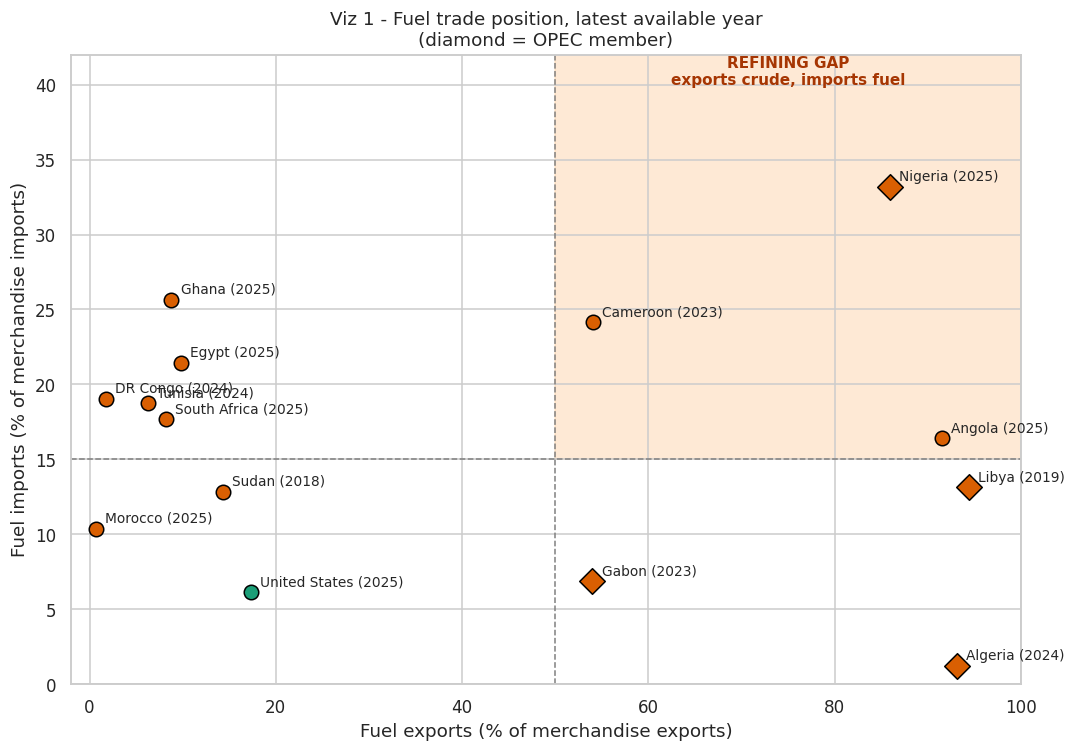

In [3]:
trade = latest.dropna(subset=["fuel_exports_pct_merchandise", "fuel_imports_pct_merchandise"])
fig, ax = plt.subplots(figsize=(10, 7))
ax.axvspan(50, 100, ymin=15 / 42, ymax=1, color="#fdd0a2", alpha=0.45, zorder=0)
ax.axvline(50, ls="--", c="grey", lw=1)
ax.axhline(15, ls="--", c="grey", lw=1)
for _, r in trade.iterrows():
    ax.scatter(r.fuel_exports_pct_merchandise, r.fuel_imports_pct_merchandise,
               s=140 if r.opec_member else 90, c=COLORS[r.region],
               marker="D" if r.opec_member else "o", edgecolor="black", zorder=3)
    ax.annotate(f"{r.country} ({int(r.fuel_exports_pct_merchandise_year)})",
                (r.fuel_exports_pct_merchandise, r.fuel_imports_pct_merchandise),
                xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.text(75, 40, "REFINING GAP\nexports crude, imports fuel", ha="center", fontsize=10,
        weight="bold", color="#a63603")
ax.set(xlim=(-2, 100), ylim=(0, 42), xlabel="Fuel exports (% of merchandise exports)",
       ylabel="Fuel imports (% of merchandise imports)",
       title="Viz 1 - Fuel trade position, latest available year\n(diamond = OPEC member)")
plt.tight_layout()
plt.show()

**Reading the chart**

* **Nigeria** is the textbook case: ~86% of exports are fuel, yet fuel is also ~33% of imports. Africa's largest crude producer has relied on imported petrol for years because its four state refineries (Port Harcourt, Warri, Kaduna) ran far below nameplate capacity; the 650 kb/d Dangote refinery, which began ramping up in 2024, is the first serious attempt to close this gap.
* **Angola** and **Cameroon** sit in the same quadrant — crude exporters with thin domestic refining.
* **Algeria**, **Libya** and **Gabon** are in the bottom-right: large exporters whose domestic refineries (Skikda, Ras Lanuf, Sogara) meet most local demand.
* The **USA** is a balanced, diversified trader — the shale boom made it a net petroleum exporter and a major supplier of refined products to West Africa.

## 3. How the refining gap evolved over time

Visualisation 2 tracks the fuel-import burden of the refining-gap countries against the USA. The 2022 spike reflects the post-invasion surge in diesel and gasoline prices; countries that import refined products felt it directly in their import bills.

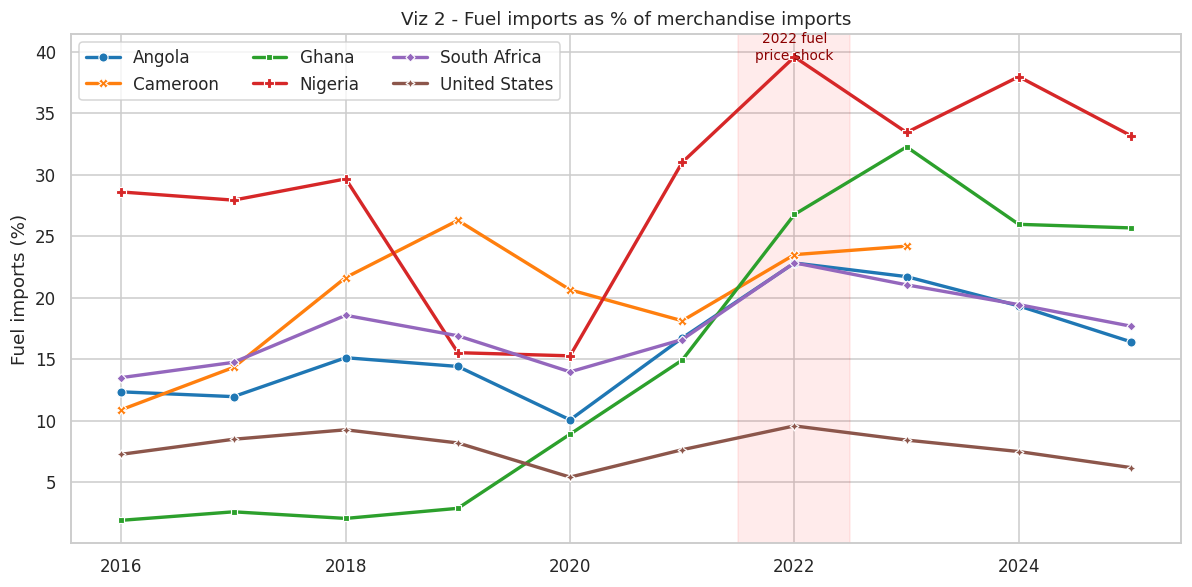

Years flagged with a refining gap:
country
Nigeria     10
Angola       6
Cameroon     5
Libya        2


In [4]:
focus = ["Nigeria", "Angola", "Cameroon", "Ghana", "South Africa", "United States"]
trend = panel[panel["country"].isin(focus) & panel["year"].between(2016, 2025)]
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.lineplot(data=trend, x="year", y="fuel_imports_pct_merchandise", hue="country",
             style="country", markers=True, dashes=False, linewidth=2.2, ax=ax,
             palette="tab10")
ax.axvspan(2021.5, 2022.5, color="red", alpha=0.08)
ax.text(2022, ax.get_ylim()[1] * 0.95, "2022 fuel\nprice shock", ha="center", fontsize=9,
        color="darkred")
ax.set(title="Viz 2 - Fuel imports as % of merchandise imports", xlabel="",
       ylabel="Fuel imports (%)")
ax.legend(title="", ncol=3, loc="upper left")
plt.tight_layout()
plt.show()

gap_years = (panel.groupby("country")["refining_gap_flag"].sum()
             .loc[lambda s: s > 0].sort_values(ascending=False))
print("Years flagged with a refining gap:")
print(gap_years.to_string())

Nigeria is flagged in **every** year with trade data (2016–2025), Angola in 6 of 10 and Cameroon in 5 of 8 — this is structural, not cyclical. Ghana is not a petro-state by our threshold, but its fuel-import share jumped from ~2–3% before 2020 to 25–32% from 2022 onwards, making it one of the most fuel-import-exposed economies in the sample.

## 4. Oil rents: dependence and volatility

Visualisation 3 is a heatmap of oil rents as a share of GDP. It highlights both the **level** of dependence and the damage done by the 2014–16 and 2020 oil-price crashes.

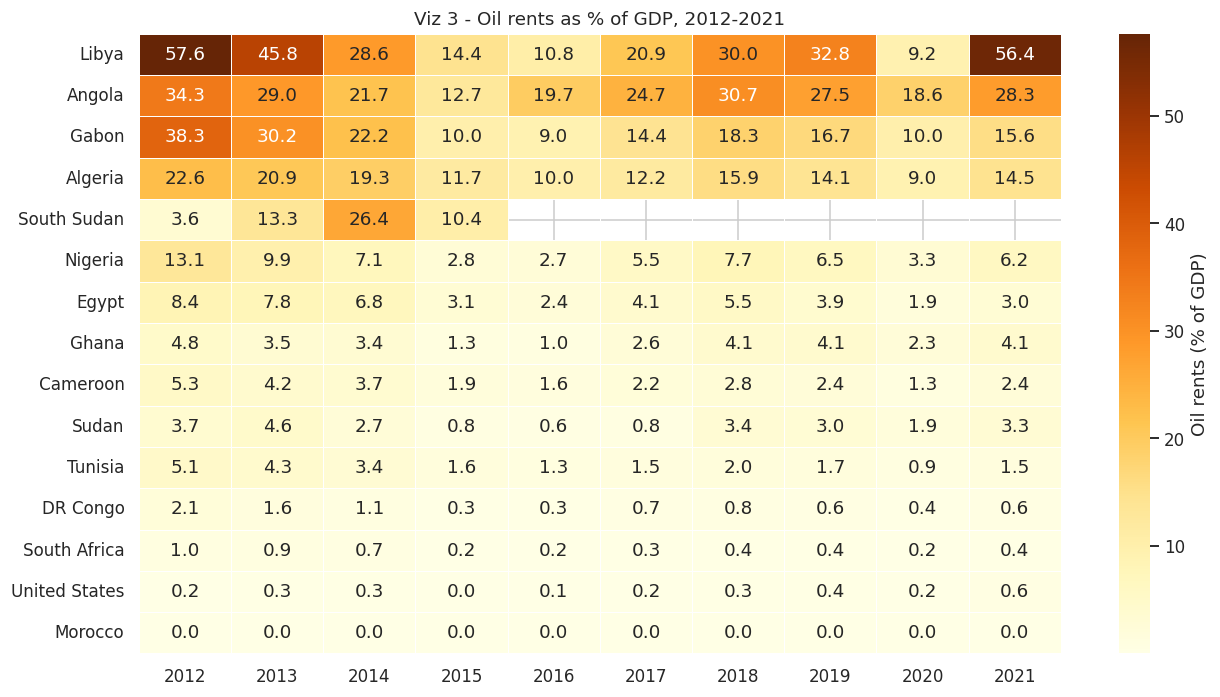

In [5]:
rents = (panel.dropna(subset=["oil_rents_pct_gdp"])
         .pivot(index="country", columns="year", values="oil_rents_pct_gdp"))
rents = rents.loc[rents.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(12, 6.5))
sns.heatmap(rents, annot=True, fmt=".1f", cmap="YlOrBr", linewidths=0.4,
            cbar_kws={"label": "Oil rents (% of GDP)"}, ax=ax)
ax.set(title="Viz 3 - Oil rents as % of GDP, 2012-2021", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

* **Libya** swings from 57.6% (2012) to 9.2% (2020, blockade of export terminals) and back to 56.4% in 2021 — the most volatile economy in the sample.
* **Angola**, **Gabon** and **Algeria** lost roughly half their oil rents between 2013 and 2015–16.
* **Nigeria's** rents are lower relative to GDP (a large non-oil economy) but oil still dominates exports and government revenue.
* The **USA** stays below 1% of GDP: despite being the world's largest crude producer, oil is a small part of a $27-trillion economy.

## 5. Energy access: the human side of the fuel gap

Visualisation 4 compares electricity access in 2015 and 2024. Fuel scarcity and electricity scarcity are linked: across much of sub-Saharan Africa, diesel and petrol generators fill the gap left by unreliable grids, so imported refined fuel literally keeps the lights on.

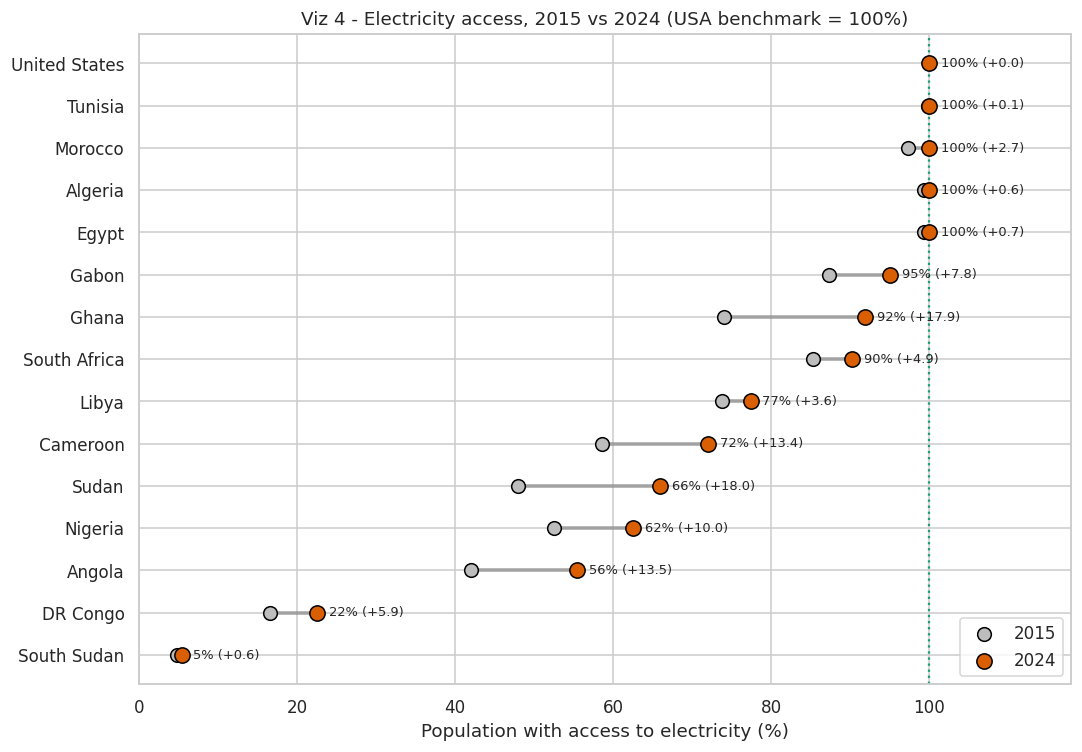

In [6]:
acc = (panel[panel["year"].isin([2015, 2024])]
       .pivot(index="country", columns="year", values="electricity_access_pct")
       .dropna().sort_values(2024))
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(acc))
ax.hlines(y, acc[2015], acc[2024], color="grey", lw=2.5, alpha=0.6)
ax.scatter(acc[2015], y, color="#bdbdbd", s=80, label="2015", zorder=3, edgecolor="black")
ax.scatter(acc[2024], y, color="#d95f02", s=100, label="2024", zorder=3, edgecolor="black")
for i, (c, row) in enumerate(acc.iterrows()):
    ax.text(row[2024] + 1.5, i, f"{row[2024]:.0f}% ({row[2024] - row[2015]:+.1f})",
            va="center", fontsize=8.5)
ax.axvline(100, c=COLORS["North America"], ls=":", lw=1.5)
ax.set_yticks(y, acc.index)
ax.set(xlim=(0, 118), xlabel="Population with access to electricity (%)",
       title="Viz 4 - Electricity access, 2015 vs 2024 (USA benchmark = 100%)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

* **South Sudan (5.4%)** and **DR Congo (22.5%)** remain among the least electrified countries on Earth — South Sudan despite earning most of its export revenue from crude piped through Sudan.
* **Sudan (+18 pp)**, **Ghana (+17.9 pp)**, **Angola (+13.5 pp)** and **Cameroon (+13.4 pp)** made the largest gains.
* **Nigeria** reached only 62.5% — tens of millions of Nigerians still have no grid power, which is why petrol subsidies and generator fuel are such potent political issues.
* North Africa (Algeria, Egypt, Morocco, Tunisia) has achieved universal access, matching the USA.

## 6. Does oil wealth buy energy access?

Visualisation 5 (interactive) plots average oil rents (2012–2021) against the latest electricity access, with bubble size proportional to GDP per capita.

In [7]:
avg_rents = (panel[panel["year"].between(2012, 2021)]
             .groupby("iso3")["oil_rents_pct_gdp"].mean().rename("avg_oil_rents_pct_gdp"))
bubble = latest.merge(avg_rents, on="iso3")
bubble["gdp_size"] = bubble["gdp_per_capita_usd"].fillna(500).clip(upper=15000)
fig = px.scatter(
    bubble, x="avg_oil_rents_pct_gdp", y="electricity_access_pct", size="gdp_size",
    color="subregion", text="country", size_max=45,
    hover_data={"gdp_per_capita_usd": ":,.0f", "gdp_size": False,
                "avg_oil_rents_pct_gdp": ":.1f", "electricity_access_pct": ":.1f"},
    labels={"avg_oil_rents_pct_gdp": "Average oil rents 2012-2021 (% of GDP)",
            "electricity_access_pct": "Electricity access, latest (%)",
            "gdp_per_capita_usd": "GDP per capita (US$)"},
    title="Viz 5 - Oil rents vs electricity access (bubble = GDP per capita, capped at $15k)")
fig.update_traces(textposition="top center")
fig.add_hline(y=60, line_dash="dot", annotation_text="Energy-poverty threshold (60%)")
fig.update_layout(height=600, template="plotly_white")
fig.show()

print("Correlation (avg oil rents vs electricity access, African countries only): "
      f"{bubble[bubble.region == 'Africa'][['avg_oil_rents_pct_gdp', 'electricity_access_pct']].corr().iloc[0, 1]:.2f}")

Correlation (avg oil rents vs electricity access, African countries only): -0.11


There is **no positive relationship** between oil rents and electricity access across Africa. Angola (≈25% of GDP from oil rents) and South Sudan (≈13%) are *resource-rich but energy-poor*, while Morocco and Tunisia — with negligible oil rents — have universal access. Oil revenue has not translated into domestic energy infrastructure, refining capacity included.

## 7. Africa vs USA benchmark

Visualisation 6 compares the African average with the USA on fuel-import burden and electricity access, alongside the income gap.

In [8]:
bench = pd.read_sql("SELECT * FROM v_regional_yearly WHERE year BETWEEN 2016 AND 2024", conn)
bench["region"] = bench["region"].replace({"North America": "United States",
                                           "Africa": "Africa (14-country avg)"})
long = bench.melt(id_vars=["region", "year"],
                  value_vars=["avg_fuel_imports_pct", "avg_electricity_access_pct"],
                  var_name="metric", value_name="value")
long["metric"] = long["metric"].map({"avg_fuel_imports_pct": "Fuel imports (% of merchandise imports)",
                                     "avg_electricity_access_pct": "Electricity access (% of population)"})
fig = px.line(long, x="year", y="value", color="region", facet_col="metric", markers=True,
              color_discrete_map={"United States": COLORS["North America"],
                                  "Africa (14-country avg)": COLORS["Africa"]},
              title="Viz 6 - Africa vs USA: fuel-import burden and electricity access")
fig.update_yaxes(matches=None, showticklabels=True)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_layout(height=450, template="plotly_white", legend_title_text="")
fig.show()

income = bench.pivot(index="year", columns="region", values="avg_gdp_per_capita_usd")
income["USA multiple"] = (income["United States"] / income["Africa (14-country avg)"]).round(1)
income.round(0)

region,Africa (14-country avg),United States,USA multiple
year,,,
2016,3349.0,57977.0,17.0
2017,3614.0,60048.0,17.0
2018,3841.0,62876.0,16.0
2019,3774.0,65228.0,17.0
2020,3252.0,64465.0,20.0
2021,3547.0,71441.0,20.0
2022,3797.0,78009.0,20.0
2023,3619.0,82587.0,23.0
2024,3710.0,86170.0,23.0


* Africa's average fuel-import share **roughly doubled** from ~10.6% (2016) to ~22.6% (2023), while the USA stayed in a 5–10% band. Rising product imports are the clearest symptom of refining capacity failing to keep pace with demand.
* The electricity-access gap narrowed from ~32 pp to ~26 pp — progress, but at ~0.7 pp per year full parity is decades away.
* The income gap **widened**: average US GDP per capita went from ~17× the African average in 2016 to ~23× in 2024.

## 8. Key insights

1. **Structural refining gap.** Nigeria (all 10 years), Angola (6/10) and Cameroon (5/8) export crude while importing refined fuel at 15–40% of their import bill. Nigeria's Dangote refinery and Angola's Cabinda/Lobito projects target exactly this gap.
2. **Fuel-import burden is rising continent-wide.** The African average fuel-import share more than doubled between 2016 and 2023, with Ghana, DR Congo and Nigeria the most exposed.
3. **Oil rents are volatile and do not buy access.** Libya, Angola, Gabon and Algeria lost about half their oil rents in the 2014–16 crash; across countries, higher oil rents do not correlate with better electricity access.
4. **Energy poverty is concentrated in Central and East Africa.** South Sudan (5%) and DR Congo (23%) trail far behind North Africa and the USA (≈100%).
5. **USA relationship.** The USA is a diversified trader with fuel at ~17% of exports and ~6% of imports. US Gulf Coast refiners are a key supplier of the gasoline and diesel that West African crude exporters import, so expanding African refining directly reshapes this trade flow.

*Limitations:* trade shares are value-based and price-sensitive; the refining-gap flag is a proxy, not a measure of nameplate capacity; oil rents end in 2021 and the fossil-fuel series ends in 2015.

In [9]:
conn.close()